# EcoDrive — 02 · Modélisation (régression de la consommation)

In [1]:
import sys
sys.path.append("../src")
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_validate, GridSearchCV
from sklearn.inspection import permutation_importance
from config import DATA, FIG, ROOT, TARGET, NUM_FEATURES, CAT_FEATURES, RANDOM_STATE
from modeles import pipeline, MoyenneParVehicule, metriques, sauver

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
df = pd.read_csv(DATA).sort_values("jour").reset_index(drop=True)

## 1. Split chronologique d'abord
Test = 20 % des trajets les plus récents, utilisé **une seule fois** à la fin. On reproduit l'usage réel :
entraîner sur le passé, prédire les semaines suivantes.

In [2]:
X, y = df[NUM_FEATURES + CAT_FEATURES], df[TARGET]
coupure = int(len(df) * 0.8)
X_train, X_test, y_train, y_test = X.iloc[:coupure], X.iloc[coupure:], y.iloc[:coupure], y.iloc[coupure:]
print(f"train : {len(X_train)} trajets | test : {len(X_test)} trajets (après le jour {df.jour.iloc[coupure]:.0f})")

train : 1740 trajets | test : 435 trajets (après le jour 293)


## 2. Comparaison en validation croisée temporelle (TimeSeriesSplit, 5 folds)

In [3]:
tscv = TimeSeriesSplit(n_splits=5)
modeles = {
    "Baseline : moyenne (Dummy)": DummyRegressor(),
    "Règle actuelle : moyenne par véhicule": MoyenneParVehicule(),
    "Régression linéaire (Ridge)": pipeline(Ridge(alpha=1.0)),
    "Arbre sans max_depth": pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE)),
    "Random Forest": pipeline(RandomForestRegressor(n_estimators=100, max_features=.5, min_samples_leaf=3, random_state=RANDOM_STATE)),
    "Gradient Boosting": pipeline(HistGradientBoostingRegressor(max_depth=6, learning_rate=.08, max_iter=300, random_state=RANDOM_STATE)),
}
lignes = []
for nom, m in modeles.items():
    cv = cross_validate(m, X_train, y_train, cv=tscv, return_train_score=True,
                        scoring=("neg_mean_absolute_error", "r2"))
    lignes.append({"modèle": nom, "MAE train": -cv["train_neg_mean_absolute_error"].mean(),
                   "MAE CV": -cv["test_neg_mean_absolute_error"].mean(),
                   "écart-type": cv["test_neg_mean_absolute_error"].std(), "R² CV": cv["test_r2"].mean()})
comp = pd.DataFrame(lignes).round(3)
comp

,modèle,MAE train,MAE CV,écart-type,R² CV
0,Baseline : moyenne (Dummy),1.986,2.018,0.100,-0.055
1,Règle actuelle : moyenne par véhicule,1.088,1.157,0.115,0.678
2,Régression linéaire (Ridge),0.673,0.753,0.115,0.849
3,Arbre sans max_depth,-0.000,0.864,0.168,0.781
4,Random Forest,0.341,0.663,0.180,0.875
5,Gradient Boosting,0.173,0.674,0.198,0.863


## 3. Réglage d'hyperparamètres (Random Forest)

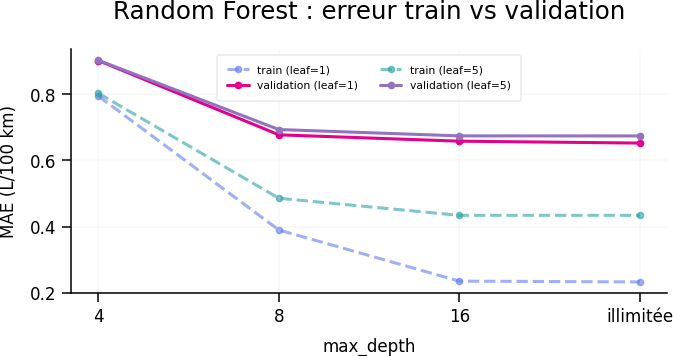

meilleurs paramètres : {'model__max_depth': None, 'model__min_samples_leaf': 1} | MAE CV : 0.652


In [4]:
grid = GridSearchCV(pipeline(RandomForestRegressor(n_estimators=100, max_features=.5, random_state=RANDOM_STATE)),
                    {"model__max_depth": [4, 8, 16, None], "model__min_samples_leaf": [1, 5]},
                    cv=tscv, scoring="neg_mean_absolute_error", return_train_score=True).fit(X_train, y_train)
res = pd.DataFrame(grid.cv_results_)
res = res.assign(MAE_train=-res.mean_train_score, MAE_CV=-res.mean_test_score)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for leaf, g in res.groupby("param_model__min_samples_leaf"):
    prof = g.param_model__max_depth.astype(str).replace("None", "illimitée")
    ax.plot(prof, g.MAE_train, "--o", alpha=.6, label=f"train (leaf={leaf})")
    ax.plot(prof, g.MAE_CV, "-o", label=f"validation (leaf={leaf})")
ax.set(title="Random Forest : erreur train vs validation", xlabel="max_depth", ylabel="MAE (L/100 km)")
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.savefig(FIG / "02_reglage_rf.png", bbox_inches="tight"); plt.show()
print("meilleurs paramètres :", grid.best_params_, "| MAE CV :", round(-grid.best_score_, 3))

**Lecture :** plus l'arbre est profond, plus l'erreur train baisse, mais pas celle de validation : sur-apprentissage.

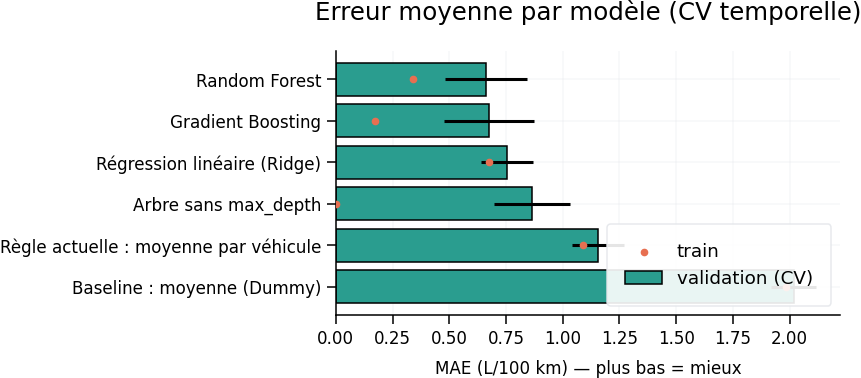

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
c = comp.sort_values("MAE CV", ascending=False)
ax.barh(c["modèle"], c["MAE CV"], xerr=c["écart-type"], color="#2a9d8f", label="validation (CV)")
ax.scatter(c["MAE train"], c["modèle"], color="#e76f51", zorder=3, label="train")
ax.set(title="Erreur moyenne par modèle (CV temporelle)", xlabel="MAE (L/100 km) — plus bas = mieux")
ax.legend(loc="lower right"); plt.tight_layout(); plt.savefig(FIG / "02_comparaison_modeles.png", bbox_inches="tight"); plt.show()

In [6]:
cands = {"Random Forest réglée": (-grid.best_score_, grid.best_estimator_),
         "Gradient Boosting": (comp.set_index("modèle").loc["Gradient Boosting", "MAE CV"], modeles["Gradient Boosting"])}
nom_final = min(cands, key=lambda k: cands[k][0])
final = cands[nom_final][1].fit(X_train, y_train)
print("modèle retenu (meilleure MAE CV) :", nom_final)

modèle retenu (meilleure MAE CV) : Random Forest réglée


## 4. Évaluation finale sur le test (une seule fois)

modèle : {'MAE': 0.72, 'RMSE': 1.026, 'R2': 0.869}
règle  : {'MAE': 1.269, 'RMSE': 1.725, 'R2': 0.628}
trajets prédits à moins de 10 % : 62%


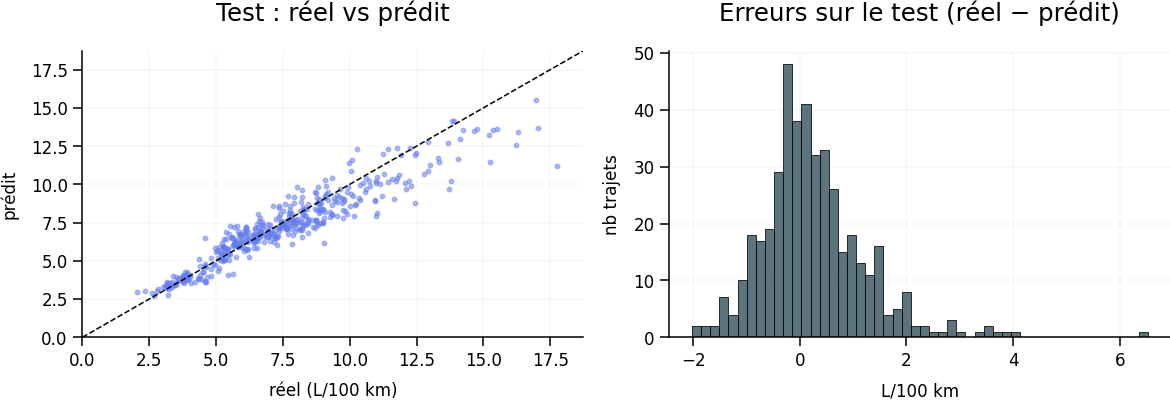

In [7]:
p_test = final.predict(X_test)
m_final = metriques(y_test, p_test)
m_regle = metriques(y_test, MoyenneParVehicule().fit(X_train, y_train).predict(X_test))
m_dummy = metriques(y_test, np.full(len(y_test), y_train.mean()))
err_rel = np.abs(y_test - p_test) / y_test
print("modèle :", {k: round(v, 3) for k, v in m_final.items()})
print("règle  :", {k: round(v, 3) for k, v in m_regle.items()})
print(f"trajets prédits à moins de 10 % : {(err_rel < .1).mean():.0%}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y_test, p_test, s=8, alpha=.5)
lim = [0, max(y_test.max(), p_test.max()) + 1]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set(xlim=lim, ylim=lim, title="Test : réel vs prédit", xlabel="réel (L/100 km)", ylabel="prédit")
sns.histplot(y_test - p_test, bins=50, ax=ax[1], color="#264653")
ax[1].set(title="Erreurs sur le test (réel − prédit)", xlabel="L/100 km", ylabel="nb trajets")
plt.tight_layout(); plt.savefig(FIG / "02_reel_vs_predit.png", bbox_inches="tight"); plt.show()

## 5. Diagnostic : importance des variables et analyse des erreurs

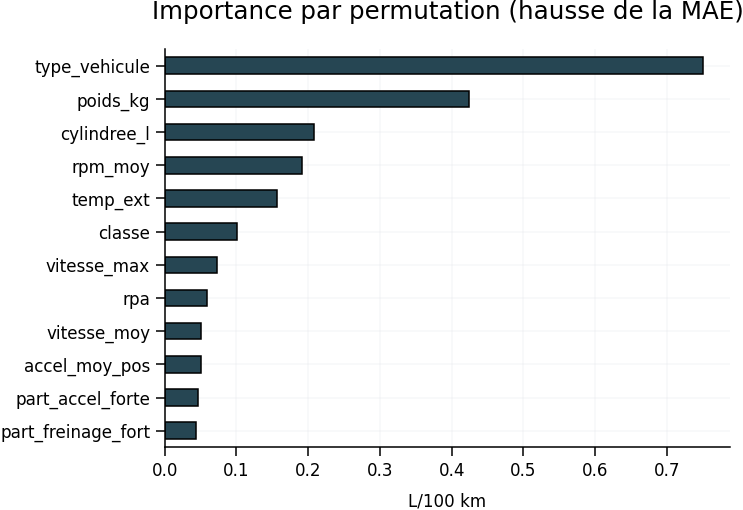

size  mean
type_vehicule contexte                   
HEV           ville/mixte        65  0.35
              mixte autoroute     5  0.35
              autoroute          14  0.31
ICE           ville/mixte       266  0.76
              mixte autoroute     9  1.02
              autoroute          76  0.96

In [8]:
pi = permutation_importance(final, X_test, y_test, n_repeats=3, random_state=RANDOM_STATE, scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
imp.tail(12).plot.barh(ax=ax, color="#264653")
ax.set(title="Importance par permutation (hausse de la MAE)", xlabel="L/100 km")
plt.tight_layout(); plt.savefig(FIG / "02_importance.png", bbox_inches="tight"); plt.show()

test = df.iloc[coupure:].assign(err=np.abs(y_test - p_test))
test["contexte"] = pd.cut(test.part_autoroute, [-.01, .2, .6, 1], labels=["ville/mixte", "mixte autoroute", "autoroute"])
analyse = test.groupby(["type_vehicule", "contexte"], observed=True).err.agg(["size", "mean"]).round(2)
analyse

**Lecture :** les erreurs sont plus fortes sur autoroute et pour les hybrides (état de la batterie non connu).
Le modèle a appris des effets physiques cohérents (véhicule, style, froid) : il est explicable au conducteur.

In [9]:
joblib.dump(final, ROOT / "reports" / "modele_conso.joblib")
sauver("regression", {"n_train": len(X_train), "n_test": len(X_test), "comparaison": comp.to_dict("records"),
                      "modele_retenu": nom_final, "params_rf": grid.best_params_, "mae_rf_reglee": float(-grid.best_score_),
                      "test_modele": m_final, "test_regle": m_regle, "test_dummy": m_dummy,
                      "pct_moins_10": float((err_rel < .1).mean()),
                      "top_variables": imp.sort_values(ascending=False).head(5).round(3).to_dict(),
                      "analyse": analyse.reset_index().astype({"contexte": str}).to_dict("records")})